## Clustering: Jerárquico aglomerativo

- Se comparan criterios de enlace; dónde cortar el árbol y se dibuja el dendrograma

- **Corre** en scipy 

- Matriz de distancias completa (n²/2)

- Proveedores no cabe en memoria; se usa una muestra

### Constantes

- `RANGO_N`: tamaños de muestra de proveedores que se prueban

- `ENLACES`: criterios para unir grupos

- `RANGO_K`: cortes del árbol que se evalúan

### Enlaces


- **Ward:** une los dos grupos cuya fusión menos aumenta la varianza interna

- **Average:** promedio de las distancias entre todos los puntos de un grupo y del otro

- **Complete:** distancia entre los dos puntos más lejanos de ambos grupos

- **Single:** distancia entre los dos puntos más cercanos de ambos grupos

In [1]:
RANGO_N = [1000, 2000, 3000, 5000, 10000]
ENLACES = ["ward", "average", "complete", "single"]
RANGO_K = list(range(2, 11))

### Utilidades

In [2]:
NOTEBOOK = "d_jerarquico"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


In [4]:
from scipy.cluster.hierarchy import linkage, fcluster, cophenet, dendrogram
from scipy.spatial.distance import pdist

config = leer_config()
datos = {}
for s, c in config.items():
    d, X = cargar_local(s, c["n_comp"])
    datos[s] = (d.merge(pd.read_parquet(datos_dir / f"kmeans_{s}"), on=c["key"]), X)
    print(f"{s}: {len(X):,} actores")

entidad: 2,696 actores
proveedor: 13,317 actores


---
### **1. Tamaño de la muestra `N_JER`**

- Muestra estratificada por clúster de KMeans, para que todas las tipologías estén representadas

- Se mide tiempo, memoria y si la partición de Ward en el k de KMeans se parece a la de KMeans (ARI)

In [5]:
tamanos = []
d, X = datos["proveedor"]
for n in [m for m in RANGO_N if m < len(X)]:
    idx = muestra_estratificada(d, n, "cluster")
    Z, seg, mb = medir(linkage, X[idx], method="ward")
    lab = fcluster(Z, config["proveedor"]["k"], criterion="maxclust") - 1
    tamanos.append({"n": len(idx), "seg": seg, "mb_pico": mb, "mb_distancias": round(len(idx) ** 2 / 2 * 8 / 1024**2, 1),
                    "ari_vs_kmeans": round(ari(lab, d.cluster.to_numpy()[idx]), 3), "silueta": round(silueta(X[idx], lab), 3)})
tamanos = pd.DataFrame(tamanos)
print(f"todos los proveedores ({len(X):,}) requerirían ~{len(X) ** 2 / 2 * 8 / 1024**3:.1f} GB solo de distancias")
tamanos

todos los proveedores (13,317) requerirían ~0.7 GB solo de distancias


,n,seg,mb_pico,mb_distancias,ari_vs_kmeans,silueta
0,1001,0.01,4.3,3.8,0.724,0.312
1,2000,0.08,17.2,15.3,0.569,0.248
2,3000,0.08,38.6,34.3,0.733,0.326
3,5000,0.26,107.3,95.4,0.538,0.355
4,10001,1.52,429.2,381.5,0.570,0.311


- La memoria crece al cuadrado: 4 MB con 1,000 proveedores, 107 MB con 5,000 y 429 MB con 10,000

- La silueta es mayor con 5,000 (0.355) que con 10,000 (0.311)

- El ARI con KMeans varía entre 0.54 y 0.73 según la muestra

- Se fija `N_JER = 5,000` proveedores: el 38% del total, con la mejor silueta y 0.1 GB por árbol

In [6]:
muestras = {"entidad": np.arange(len(datos["entidad"][1])),
            "proveedor": muestra_estratificada(datos["proveedor"][0], N_JER, "cluster")}
for s, idx in muestras.items():
    print(f"{s}: {len(idx):,} actores en el jerárquico")

entidad: 2,696 actores en el jerárquico
proveedor: 5,000 actores en el jerárquico


---
### **2. Criterio de enlace**

- **Cofenética:** qué tan bien el árbol conserva las distancias originales (1 = perfecto)

- **Silueta** al cortar en el k de KMeans y **tamaño del grupo mayor**

In [7]:
enlaces, arboles = [], {}
for s, (d, X) in datos.items():
    Xs = X[muestras[s]]; dist = pdist(Xs)
    for e in ENLACES:
        Z = linkage(Xs, method=e)
        arboles[(s, e)] = Z
        lab = fcluster(Z, config[s]["k"], criterion="maxclust") - 1
        enlaces.append({"sujeto": s, "enlace": e, "cofenetica": round(cophenet(Z, dist)[0], 3),
                        "silueta": round(silueta(Xs, lab), 3), "pct_grupo_mayor": round(100 * np.bincount(lab).max() / len(lab), 1)})
enlaces = pd.DataFrame(enlaces)
enlaces.pivot(index="enlace", columns="sujeto", values=["cofenetica", "silueta", "pct_grupo_mayor"])

cofenetica           silueta           pct_grupo_mayor          
sujeto      entidad proveedor entidad proveedor         entidad proveedor
enlace                                                                   
average       0.670     0.796   0.467     0.353            99.0      93.9
complete      0.272     0.618   0.062     0.183            51.7      62.4
single        0.671     0.606   0.443     0.563            99.9      99.9
ward          0.352     0.683   0.122     0.355            34.7      77.6

- **Average y single** tienen la mejor cofenética y silueta, pero dejan al **94-99.9% de los actores en un solo grupo**

- **Complete** da grupos parejos en entidades, pero con silueta muy baja (0.06)

- **Ward** minimiza la varianza dentro de cada grupo, igual que KMeans: es el único con grupos balanceados 

- 35% en el mayor en entidades, 78% en proveedores, y buena silueta en proveedores (0.355)

- Se fija `ENLACE = "ward"`

---
### **3. Corte del árbol**

In [8]:
cortes = []
for s in datos:
    Xs = datos[s][1][muestras[s]]
    for k in RANGO_K:
        lab = fcluster(arboles[(s, ENLACE)], k, criterion="maxclust") - 1
        cortes.append({"sujeto": s, "k": k, "silueta": round(silueta(Xs, lab), 3),
                       "pct_grupo_mayor": round(100 * np.bincount(lab).max() / len(lab), 1),
                       "pct_grupo_menor": round(100 * np.bincount(lab).min() / len(lab), 1)})
cortes = pd.DataFrame(cortes)
cortes.pivot(index="k", columns="sujeto", values=["silueta", "pct_grupo_mayor", "pct_grupo_menor"])

silueta           pct_grupo_mayor           pct_grupo_menor          
sujeto entidad proveedor         entidad proveedor         entidad proveedor
k                                                                           
2        0.145     0.343            52.3      91.4            47.7       8.6
3        0.131     0.336            52.3      81.7            13.0       8.6
4        0.122     0.355            34.7      77.6            13.0       4.1
5        0.102     0.357            26.9      77.6             8.0       3.8
6        0.102     0.199            26.7      45.0             8.0       3.8
7        0.108     0.191            26.7      32.6             2.3       3.8
8        0.115     0.200            25.4      32.6             2.3       3.8
9        0.118     0.189            20.7      25.0             2.3       3.8
10       0.086     0.187            18.3      25.0             2.3       1.7

- **Entidades:** la silueta es baja en todos los cortes (0.09-0.15). k = 2 es el máximo

- **Proveedores:** la silueta es máxima en k = 4-5 (0.355-0.357) y cae a 0.20 desde k = 6

- Se fija `K_JER = 4` en ambos: está en el máximo de proveedores y permite compararlo uno a uno con KMeans

In [9]:
for s in config:
    config[s].update(jerarquico={"enlace": ENLACE, "k": K_JER[s], "n": len(muestras[s])})
guardar_config(config)

---
### **4. Dendrograma**

- Truncado a los últimos 30 grupos

- La línea roja es el corte en `K_JER`

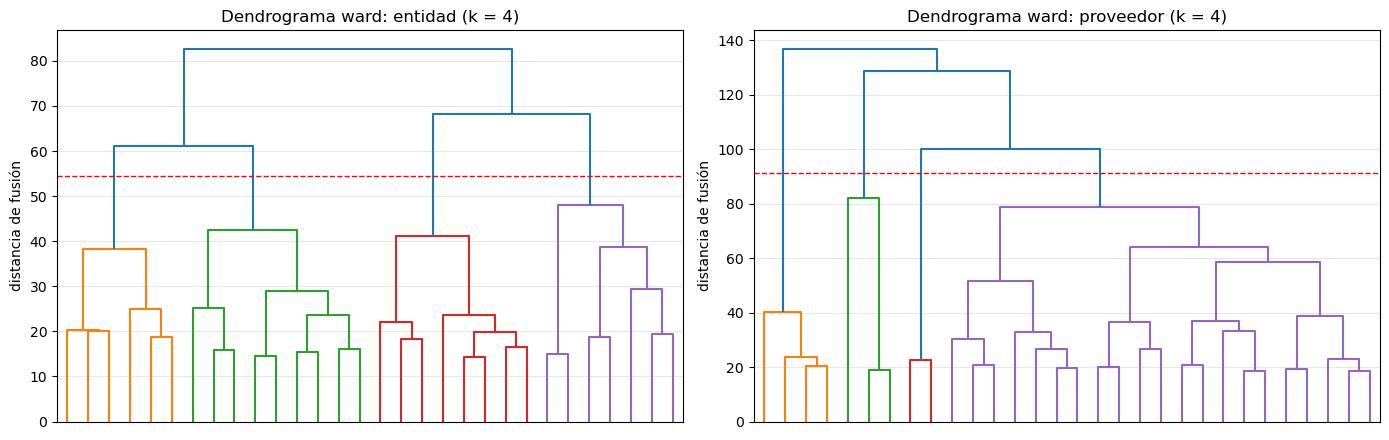

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for i, s in enumerate(datos):
    Z = arboles[(s, ENLACE)]
    corte = (Z[-K_JER[s], 2] + Z[-K_JER[s] + 1, 2]) / 2
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax[i], color_threshold=corte, no_labels=True)
    ax[i].axhline(corte, color="red", ls="--", lw=1)
    ax[i].set_title(f"Dendrograma {ENLACE}: {s} (k = {K_JER[s]})"); ax[i].set_ylabel("distancia de fusión")
mostrar_fig("dendrograma")

- **Proveedores:** tres grupos chicos se separan muy arriba, con ramas largas 

- Son perfiles bien diferenciados (multicliente, sin competencia, obras) frente a una gran masa típica

- **Entidades:** cuatro grupos de tamaño parecido, que se unen de forma escalonada (~40 → 60-68 → 83), sin un salto claro. 

- Es lo mismo que mostró la silueta baja: los perfiles de entidad se separan menos

---
### **5. Comparación con KMeans y perfiles**

In [11]:
perfiles, comp = {}, []
for s, (d, X) in datos.items():
    idx = muestras[s]; key = config[s]["key"]
    lab = fcluster(arboles[(s, ENLACE)], K_JER[s], criterion="maxclust") - 1
    r = d.iloc[idx][[key, "cluster"]].rename(columns={"cluster": "kmeans"}).assign(jerarquico=lab)
    r.to_parquet(datos_dir / f"jerarquico_{s}", index=False)
    comp.append({"sujeto": s, "n": len(idx), "ari_vs_kmeans": round(ari(r.kmeans, r.jerarquico), 3)})
    perfiles[s] = perfil_z(d.iloc[idx].assign(jerarquico=lab), config[s]["feats"], "jerarquico")[["rasgos"]].assign(
        n=pd.Series(lab).value_counts().sort_index().to_numpy())
    print(f"{s}: grupos de Ward (filas) × tipologías de KMeans (columnas)")
    display(pd.crosstab(r.jerarquico, r.kmeans, rownames=["jerárquico"], colnames=["kmeans"]))
comp = pd.DataFrame(comp)
print("resumen: ARI entre Ward y KMeans")
comp

entidad: grupos de Ward (filas) × tipologías de KMeans (columnas)


kmeans,0,1,2,3
jerárquico,,,,
0,53,15,479,137
1,551,7,165,3
2,19,212,2,118
3,286,0,34,615


proveedor: grupos de Ward (filas) × tipologías de KMeans (columnas)


kmeans,0,1,2,3
jerárquico,,,,
0,427,0,0,2
1,7,8,466,7
2,0,1,0,203
3,465,3089,154,171


resumen: ARI entre Ward y KMeans


,sujeto,n,ari_vs_kmeans
0,entidad,2696,0.356
1,proveedor,5000,0.538


In [12]:
display(perfiles["entidad"]); display(perfiles["proveedor"])

,rasgos,n
jerarquico,,
0,"pct_obras ↑1.1σ, log_monto_mediano ↑0.7σ, pct_bienes ↓0.6σ",684
1,"share_top_proveedores ↑0.9σ, log_n_procesos ↓0.8σ, log_monto_total ↓0.8σ",726
2,"pct_postor_unico ↑1.8σ, pct_directa ↑1.7σ, pct_obras ↓0.6σ",351
3,"log_n_procesos ↑0.7σ, share_top_proveedores ↓0.6σ, log_postores_promedio ↑0.5σ",935


,rasgos,n
jerarquico,,
0,"meses_activos ↑2.4σ, log_n_entidades ↑2.1σ, log_n_regiones ↑1.9σ",429
1,"pct_postor_unico ↑2.5σ, tasa_exito ↑1.8σ, pct_directa ↑1.4σ",488
2,"pct_obras ↑4.7σ, log_monto_mediano ↑1.9σ, log_monto_total ↑1.2σ",204
3,"pct_postor_unico ↓0.3σ, meses_activos ↓0.2σ, pct_obras ↓0.2σ",3879


- **Proveedores:** ARI 0.54 con KMeans. Ward encuentra los mismos perfiles

- Multicliente (entidades ↑), sin competencia (postor único ↑), obras (obras ↑4.7σ) y uno grande típico

- **Entidades:** ARI 0.36. Ward reproduce obras, sin competencia y grandes, pero reparte de otro modo a las pequeñas

- Dos métodos distintos llegan a **perfiles parecidos**: las tipologías no son un artefacto de KMeans

#### a. Verificación

In [13]:
for s in config:
    r = pd.read_parquet(datos_dir / f"jerarquico_{s}")
    assert r[config[s]["key"]].is_unique and len(r) == len(muestras[s]) and r.jerarquico.nunique() == K_JER[s], s
    print(f"{s}: {len(r):,} etiquetas en {K_JER[s]} grupos | OK")

entidad: 2,696 etiquetas en 4 grupos | OK
proveedor: 5,000 etiquetas en 4 grupos | OK


---
### **6. Escritura de resultados**

In [14]:
escritos = guardar_tablas({"tamano_muestra": tamanos, "enlaces": enlaces, "cortes": cortes, "ari_jerarquico": comp,
                           "perfiles_jerarquico": pd.concat({s: p.reset_index() for s, p in perfiles.items()}).reset_index(level=0)
                                                    .rename(columns={"level_0": "sujeto"})})

Escrito en 02_Clustering/temp/d_jerarquico/: tamano_muestra, enlaces, cortes, ari_jerarquico, perfiles_jerarquico


#### a. Verificación

In [15]:
verificar_salidas(escritos)

OK: 5 tablas (parquet + json) | 1 figuras: dendrograma


---
### **7. Cerrar sesión**

In [16]:
spark.stop()